# 3. From a score to a decision

> **In plain terms.** A risk is only useful once you choose a cut-off for acting on it. Lowering the cut-off to 0.24 catches 85% of cases instead of 57%, at the cost of more false alarms. The risks themselves can be trusted, but the model works worst for women 45 and over. (Milestone 5, notebook 07, later replaces the 85% rule with a cut-off chosen from costs.)

A model outputs a probability. Someone still has to decide what probability is high enough to act on. This notebook picks that cut-off for a screening setting, checks that the probabilities are believable, and exports the final model for the web page.

New to the terms? The [glossary](../docs/GLOSSARY.md) explains every one, and the [overview](../docs/OVERVIEW.md) covers the whole project in five minutes.

In [1]:
import sys, warnings
sys.path.insert(0, "..")          # so the notebook can import the project's src/ folder
warnings.filterwarnings("ignore")
import pandas as pd
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")

## 3.1 One honest prediction per woman

**What we're looking for.** A predicted probability for every woman, made by a model that never saw her during training.

In [2]:
from sklearn.metrics import roc_auc_score
from src.data import load_data
from src.evaluate import out_of_fold, bootstrap_auc, confusion_at
from src.modeling import logistic

X, y = load_data()
p = out_of_fold(logistic(), X, y)       # average of each woman's 10 held-out predictions
lo, hi = bootstrap_auc(y, p)
print(f"AUC {roc_auc_score(y, p):.3f}   95% interval {lo:.3f} to {hi:.3f}")
pd.Series(confusion_at(y, p, 0.50))

AUC 0.836   95% interval 0.807 to 0.863


threshold         0.500
tp              152.000
fp               61.000
fn              116.000
tn              439.000
sensitivity       0.567
specificity       0.878
ppv               0.714
npv               0.791
flagged_share     0.277
accuracy          0.770
dtype: float64

**How to read it.** `tp` are women with diabetes who were flagged, `fn` are women with diabetes who were missed, `fp` are healthy women flagged by mistake, and `tn` are healthy women correctly cleared. Sensitivity is tp / (tp + fn). Specificity is tn / (tn + fp). `ppv` is the share of flagged women who do have diabetes.

**What it means.** The AUC is 0.836, and the interval says the true value is plausibly anywhere from 0.81 to 0.86. At the default cut-off of 0.50 the model catches 152 of 268 cases (57%) and misses 116.

**What's next and why.** For screening, a missed case costs more than a false alarm (a false alarm leads to a follow-up blood test). So look at what a lower cut-off buys.

## 3.2 Choosing the cut-off

**What we're looking for.** The cut-off that catches at least 85% of true cases, and what it costs in false alarms.

Highest cut-off that still catches 85% of cases: 0.24


,default 0.50,screening 0.24
threshold,0.500,0.240
tp,152.000,229.000
fp,61.000,188.000
fn,116.000,39.000
tn,439.000,312.000
sensitivity,0.567,0.854
specificity,0.878,0.624
ppv,0.714,0.549
npv,0.791,0.889
flagged_share,0.277,0.543


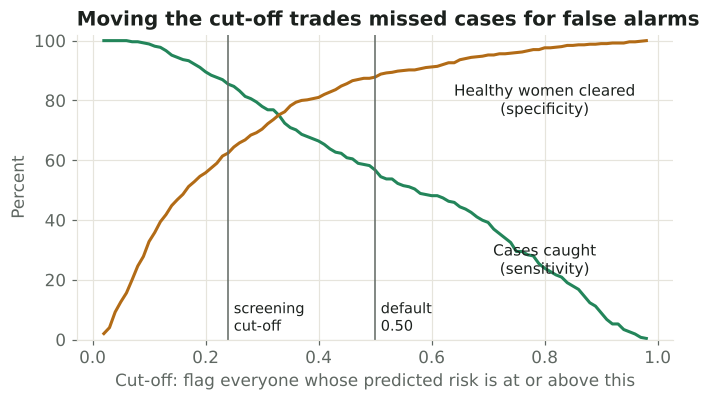

In [3]:
from src.evaluate import pick_threshold, TARGET_SENSITIVITY
from src import figures
t = pick_threshold(y, p)
print(f"Highest cut-off that still catches {TARGET_SENSITIVITY:.0%} of cases: {t:.2f}")
display(pd.DataFrame([confusion_at(y, p, 0.50), confusion_at(y, p, t)], index=["default 0.50", f"screening {t:.2f}"]).T)
figures.threshold_tradeoff();

**How to read it.** The green line is the share of true cases caught at each cut-off. The orange line is the share of healthy women correctly cleared. Moving left catches more cases and raises more false alarms.

**What it means.** Lowering the cut-off from 0.50 to 0.24 raises cases caught from 57% to 85% (229 of 268) and cuts missed cases from 116 to 39. The price is 188 false alarms instead of 61, and 54% of all women get flagged. Of those flagged, 55% do have diabetes. Whether that trade is worth it depends on what a follow-up test costs. The 85% target is a judgment call, not something the data decides.

**What's next and why.** Check the model against the simplest rule a clinic could use instead.

## 3.3 Does it beat a one-number rule?

**What we're looking for.** A comparison with "flag anyone whose 2-hour glucose is 140 mg/dL or more", the standard line for impaired glucose tolerance.

In [4]:
rule = confusion_at(y, X["Glucose"].fillna(0).to_numpy(), 140)
model_same_alarms = confusion_at(y, p, 0.50)
pd.DataFrame([rule, model_same_alarms], index=["glucose >= 140", "model at 0.50"])[
    ["tp", "fn", "fp", "tn", "sensitivity", "specificity"]]

,tp,fn,fp,tn,sensitivity,specificity
glucose >= 140,135,133,62,438,0.504,0.876
model at 0.50,152,116,61,439,0.567,0.878


**How to read it.** Two ways of flagging women, chosen because they raise almost the same number of false alarms (62 and 61), so the cases caught can be compared directly.

**What it means.** For the same number of false alarms, the model catches 152 cases and the glucose rule catches 135. That is 17 more women found, a real but modest gain. Glucose does most of the work, which matches notebook 2.

**What's next and why.** A cut-off only makes sense if the probabilities themselves can be believed, so check calibration.

## 3.4 Can the probabilities be believed?

**What we're looking for.** Whether women given a 30% risk turn out to have diabetes about 30% of the time.

Calibration slope 0.96 (ideal 1.00), intercept -0.03 (ideal 0.00), Brier 0.157


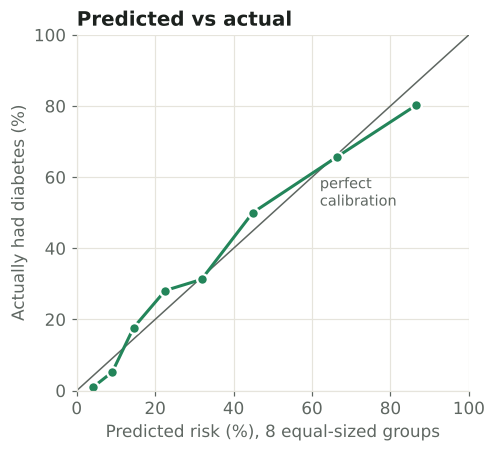

In [5]:
from src.evaluate import calibration
cal = calibration(y, p)
print(f"Calibration slope {cal['slope']:.2f} (ideal 1.00), intercept {cal['intercept']:.2f} (ideal 0.00), Brier {cal['brier']:.3f}")
figures.calibration_plot();

**How to read it.** The women are sorted by predicted risk and cut into 8 equal groups. Each dot plots a group's average predicted risk against the share who really had diabetes. Dots on the diagonal mean the probabilities are accurate.

**What it means.** The dots stay close to the diagonal and the slope is 0.96, so the probabilities are well calibrated for this group of women. A predicted 30% does mean roughly 3 in 10. That holds only for a population like this one, where 35% have diabetes.

**What's next and why.** An average can hide groups the model serves badly, so split the results by age.

## 3.5 Who does it work less well for?

**What we're looking for.** The same cut-off applied to three age bands.

In [6]:
from src.evaluate import by_age
pd.DataFrame(by_age(X, y, p, t)).set_index("band")

,n,cases,prevalence,auc,sensitivity,specificity,missed
band,,,,,,,
21 to 29,396,84,0.212,0.858,0.798,0.760,17
30 to 44,239,118,0.494,0.791,0.864,0.496,16
45 and over,133,66,0.496,0.734,0.909,0.224,6


**How to read it.** Each row is an age band. `prevalence` is the share with diabetes in that band. Sensitivity and specificity use the screening cut-off from 3.2.

**What it means.** Diabetes is far less common under 30 (21%) than over 30 (about 49%). With one cut-off for everyone, the model catches 80% of cases in the youngest band and 91% in the oldest, but it clears only 22% of healthy women aged 45 and over. For older women it flags nearly everyone, which makes it close to useless as a filter there. The AUC also falls with age, from 0.86 to 0.73.

**What's next and why.** This is the main weakness to work on. Milestone 3 tests whether letting the effect of age and glucose bend (rather than follow a straight line) fixes it (E10).

## 3.6 The final model

**What we're looking for.** What the model leans on, and the export the web page uses.

,odds multiplier per 1 SD,1 SD is,unit
Glucose,3.108,30.418,mg/dL
BMI,1.888,6.871,kg/m2
Pregnancies,1.513,3.367,count
DiabetesPedigreeFunction,1.332,0.331,score
Age,1.166,11.753,years
SkinThickness,1.036,8.785,mm
Insulin,0.911,86.327,mu U/mL
BloodPressure,0.899,12.089,mm Hg


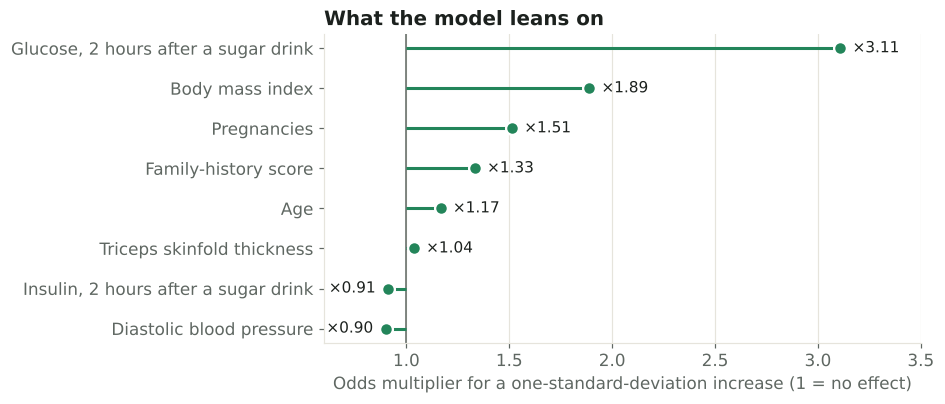

In [7]:
import json
from src.evaluate import export_model
from src.data import LABELS
model = export_model(X, y)              # fitted on all 768 women
display(pd.DataFrame({
    "odds multiplier per 1 SD": model["odds_ratio_per_sd"],
    "1 SD is": model["scale"],
    "unit": [LABELS[f][1] for f in model["features"]],
}, index=model["features"]).sort_values("odds multiplier per 1 SD", ascending=False))
figures.odds_ratios(model);

**How to read it.** Each row is an input. The multiplier says how much the odds of diabetes change when that input rises by one standard deviation (a typical step), with the others held fixed. Above 1 raises the odds, below 1 lowers them, and 1 means no effect.

**What it means.** Glucose dominates: a 30 mg/dL rise roughly triples the odds. BMI (×1.9 per 7 points) and pregnancies (×1.5 per 3) follow. Insulin and blood pressure come out slightly below 1, which looks odd but is common when inputs overlap: once glucose is known, insulin adds little, and half of it was filled in anyway. These are associations in this group of women, not causes.

**What's next and why.** This eight-input model is the Milestone 1 baseline. Notebook 4 (Milestone 2) takes on the biggest loose end, the 49% of insulin values that are missing, and ends by changing which inputs the published model uses.